# Ergänzung: Logistische Regression genauer verstehen

Dieses Notebook erklärt die in [Notebook 3](03_Modellvergleich.ipynb) gewählte Einstellung dieses Modelltyps an einem Beispiel. Der gemeinsame Vergleich steht in [Notebook 4](04_Gewinner_Modell.ipynb).

Wir behalten die gewählten Merkmale und Einstellungen bei.


In [1]:
# Gestaltung der Abbildungen.
import json
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import font_manager as fm
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
COLORS = {'dk2': '#732124', 'lt2': '#F0EDE5', 'accent1': '#D34817', 'accent2': '#A68D65', 'accent3': '#728377', 'accent4': '#B4797B', 'accent5': '#CE8439', 'accent6': '#CF3A2A', 'hlink': '#D06853', 'folHlink': '#B67779'}
MAJOR_FONTS = ('Rockwell Nova Light', 'Rockwell Nova', 'Rockwell', 'DejaVu Serif')
MINOR_FONTS = ('Avenir Next LT Pro Light', 'Avenir Next LT Pro', 'Avenir Next', 'Calibri Light', 'Calibri', 'DejaVu Sans')
LEAF_CMAP = LinearSegmentedColormap.from_list('leaf', [COLORS['lt2'], COLORS['accent4'], COLORS['dk2']])
LEAF_CMAP.set_bad(COLORS['lt2'])

def style_leaf_tree(annotations):
    cream = to_rgb(COLORS['lt2'])
    for annotation in annotations:
        text = annotation.get_text()
        color = COLORS['accent3'] if 'class = Überlebt' in text else COLORS['accent1'] if 'class = Nicht überlebt' in text else COLORS['accent2']
        annotation.set_color(COLORS['dk2'])
        bbox = annotation.get_bbox_patch()
        if bbox is not None:
            tint = tuple((0.14 * c + 0.86 * b for c, b in zip(to_rgb(color), cream)))
            bbox.set_facecolor(tint)
            bbox.set_edgecolor(color)
            bbox.set_linewidth(0.9)
        if annotation.arrow_patch is not None:
            annotation.arrow_patch.set_color(COLORS['accent2'])

def resolved_fonts():
    available = {font.name for font in fm.fontManager.ttflist}
    major = next((name for name in MAJOR_FONTS if name in available))
    minor = next((name for name in MINOR_FONTS if name in available))
    return {'requested_heading': MAJOR_FONTS[0], 'heading': major, 'requested_body': MINOR_FONTS[0], 'body': minor, 'heading_file': fm.findfont(fm.FontProperties(family=major)), 'body_file': fm.findfont(fm.FontProperties(family=minor))}

def apply_leaf_theme():
    fonts = resolved_fonts()
    mpl.rcParams.update({'font.family': fonts['body'], 'font.size': 11, 'font.weight': 'normal', 'text.color': COLORS['dk2'], 'figure.facecolor': COLORS['lt2'], 'axes.facecolor': COLORS['lt2'], 'savefig.facecolor': COLORS['lt2'], 'savefig.transparent': False, 'axes.edgecolor': COLORS['accent2'], 'axes.linewidth': 0.7, 'axes.labelcolor': COLORS['dk2'], 'axes.labelsize': 11, 'axes.labelpad': 10, 'axes.titlesize': 13, 'axes.titleweight': 'normal', 'axes.titlepad': 14, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True, 'axes.prop_cycle': cycler(color=[COLORS[f'accent{i}'] for i in range(1, 7)]), 'xtick.color': COLORS['dk2'], 'ytick.color': COLORS['dk2'], 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'xtick.major.size': 0, 'ytick.major.size': 0, 'xtick.major.pad': 7, 'ytick.major.pad': 7, 'grid.color': COLORS['accent2'], 'grid.alpha': 0.22, 'grid.linewidth': 0.6, 'grid.linestyle': '-', 'legend.frameon': False, 'legend.fontsize': 10, 'lines.linewidth': 1.7, 'patch.linewidth': 0.8, 'boxplot.boxprops.color': COLORS['dk2'], 'boxplot.whiskerprops.color': COLORS['dk2'], 'boxplot.capprops.color': COLORS['dk2'], 'boxplot.medianprops.color': COLORS['dk2'], 'boxplot.flierprops.markeredgecolor': COLORS['dk2'], 'boxplot.flierprops.markerfacecolor': COLORS['lt2'], 'savefig.dpi': 300})
    return fonts

def _wrap_to_width(text, renderer, font_properties, max_width):
    lines = []
    for paragraph in text.split('\n'):
        line = ''
        for word in paragraph.split():
            candidate = f'{line} {word}'.strip()
            width = renderer.get_text_width_height_descent(candidate, font_properties, False)[0]
            if line and width > max_width:
                lines.append(line)
                line = word
            else:
                line = candidate
        lines.append(line)
    return '\n'.join(lines)

def decorate_leaf_figure(fig, number, title, note):
    fonts = resolved_fonts()
    heading = fm.FontProperties(family=fonts['heading'], size=17)
    body = fm.FontProperties(family=fonts['body'], size=9)
    fig.set_facecolor(COLORS['lt2'])
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width_pixels, height_pixels = (fig.bbox.width, fig.bbox.height)
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
    title_text = _wrap_to_width(title, renderer, heading, 0.91 * width_pixels)
    note_text = _wrap_to_width('Anmerkung. ' + note, renderer, body, 0.91 * width_pixels)
    number_label = f'{number:02d}' if isinstance(number, int) else str(number)
    top_label = fig.text(0.045, 0.965, f'ABBILDUNG {number_label}', color=COLORS['accent1'], family=fonts['body'], fontsize=9, va='top')
    title_artist = fig.text(0.045, 0.91, title_text, fontproperties=heading, color=COLORS['dk2'], va='top', linespacing=1.12)
    note_artist = fig.text(0.045, 0.035, note_text, fontproperties=body, color=COLORS['dk2'], va='bottom', linespacing=1.3)
    fig.canvas.draw()
    title_box = title_artist.get_window_extent(renderer)
    note_box = note_artist.get_window_extent(renderer)
    top = title_box.y0 / height_pixels - 0.055
    bottom = note_box.y1 / height_pixels + 0.055
    if top - bottom < 0.28:
        raise ValueError('Figure is too short for its title/note; increase figsize height.')
    if fig.legends:
        for legend in fig.legends:
            for text in legend.get_texts():
                text.set_text(deutsch(text.get_text()))
            legend.set_loc('upper center')
            legend.set_bbox_to_anchor((0.5, top))
        fig.canvas.draw()
        top = min((legend.get_window_extent(renderer).y0 / height_pixels for legend in fig.legends)) - 0.035
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
        if ax.get_legend() is not None:
            for text in ax.get_legend().get_texts():
                text.set_text(deutsch(text.get_text()))
        ax.set_facecolor(COLORS['lt2'])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        is_colorbar = hasattr(ax, '_colorbar')
        if ax.images or is_colorbar:
            ax.grid(False)
        elif ax.axison:
            horizontal = any((getattr(container, 'orientation', None) == 'horizontal' for container in ax.containers))
            horizontal = horizontal or 'fehlender' in ax.get_xlabel() or ax.get_xlabel() == 'Beobachtete Überlebensquote'
            ax.grid(axis='x' if horizontal else 'y')
        ax.title.set_fontfamily(fonts['heading'])
        ax.set_axisbelow(True)
    fig.add_artist(Line2D([0.045, 0.12], [top + 0.027, top + 0.027], transform=fig.transFigure, color=COLORS['accent1'], linewidth=2.5, solid_capstyle='butt'))
    fig.add_artist(Line2D([0.045, 0.955], [bottom - 0.022, bottom - 0.022], transform=fig.transFigure, color=COLORS['accent2'], linewidth=0.6, alpha=0.55))
    fig.tight_layout(rect=[0.025, bottom, 0.98, top], pad=1.1, w_pad=2.5)
    return (top_label, title_artist, note_artist)

def save_leaf_figure(fig, number, title, note, destination, *, show=True, dpi=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    decorate_leaf_figure(fig, number, deutsch(title), deutsch(note))
    fig.savefig(destination.with_suffix('.png'), dpi=dpi)
    if show:
        plt.show()
    plt.close(fig)

import pandas as pd
from IPython.display import display as _display

BEZEICHNUNGEN = {
    'Accuracy': 'Genauigkeit', 'CV-Accuracy': 'Mittlere Prüfgenauigkeit',
    'CV-F1': 'Mittlerer F1-Wert', 'CV-ROC AUC': 'Mittlere Fläche unter der Prüfkurve',
    'CV-Brier': 'Mittlerer Wahrscheinlichkeitsfehler', 'Fold-SD': 'Streuung der Prüfergebnisse',
    'Precision': 'Anteil richtiger Überlebensvorhersagen', 'Recall': 'Anteil erkannter Überlebender',
    'F1': 'F1-Wert', 'ROC AUC': 'Fläche unter der Prüfkurve',
    'Brier score': 'Wahrscheinlichkeitsfehler', "Cohen's kappa": 'Übereinstimmung über Zufallsniveau',
    'Feature': 'Merkmal', 'Coefficient': 'Gewicht', 'Feature importance': 'Merkmalsbedeutung',
    'Distance': 'Abstand', 'VoteWeight': 'Stimmgewicht', 'VoteShare': 'Stimmanteil',
    'Mean': 'Mittelwert', 'Standard deviation': 'Standardabweichung',
    '25% Quantile': 'Unteres Viertel', '75% Quantile': 'Oberes Viertel',
    'Binary target': 'Ergebnis mit zwei Werten', 'Ordinal category': 'Geordnete Kategorie',
    'Nominal category': 'Ungeordnete Kategorie', 'Candidate': 'Kombination',
    'Fold': 'Prüfdurchgang', 'Rank': 'Rang', 'Training': 'Genauigkeit in den Lerndaten',
    'Encoded columns': 'Anzahl aufbereiteter Merkmale',
    'Known holdout Accuracy': 'Genauigkeit im Kontrollvergleich',
    'Nested Personen Accuracy': 'Zusätzliche Prüfgenauigkeit (Personen)',
    'Nested Ticketgruppen Accuracy': 'Zusätzliche Prüfgenauigkeit (Ticketgruppen)',
    'Logistic Regression': 'Logistische Regression', 'Decision Tree': 'Entscheidungsbaum',
    'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
    'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
    'female': 'Weiblich', 'n_neighbors': 'Anzahl Nachbarn', 'p': 'Abstandsmaß', 'weights': 'Gewichtung', 'uniform': 'Gleichmäßig', 'distance': 'Nach Abstand', 'male': 'Männlich', 'Other': 'Sonstige',
    'Train': 'Trainingsdaten', 'Kaggle-Test': 'Testdaten',
}

def display(*werte):
    for wert in werte:
        if isinstance(wert, (pd.DataFrame, pd.Series)):
            wert = wert.copy()
            if isinstance(wert, pd.Series):
                wert = wert.to_frame()
            wert = wert.rename(columns=BEZEICHNUNGEN, index=BEZEICHNUNGEN)
            for spalte in wert.select_dtypes(include=['object', 'str']).columns:
                wert[spalte] = wert[spalte].replace(BEZEICHNUNGEN)
        if isinstance(wert, Markdown):
            wert = Markdown(deutsch(wert.data))
        _display(wert)


def deutsch(text):
    for vorher, nachher in {
        'Logistic Regression': 'Logistische Regression',
        'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
        'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
        'Decision Tree': 'Entscheidungsbaum',
        'Confusion Matrices': 'Richtige und falsche Vorhersagen',
        'Accuracy': 'Genauigkeit', 'Nested Personen-CV': 'zusätzlichen Personenprüfung',
        'Nested CV': 'zusätzliche Prüfung der Auswahl',
        'Outer fold': 'äußerer Prüfdurchgang', 'Auswahl-Folds': 'Prüfdurchgänge',
        'Training fold': 'Lerngruppe', 'Training folds': 'Lerngruppen',
        'Bekanntes Holdout': 'Kontrollvergleich', 'bekanntes Holdout': 'Kontrollvergleich', 'Holdout': 'Kontrolldatensatz',
        'Featuregruppe': 'Merkmalsgruppe', 'Feature': 'Merkmal',
        'Mean': 'Mittelwert', 'Target': 'Überleben',
        'standardized': 'bei gleicher Gruppenzusammensetzung',
        'Standardization': 'Angleichung der Gruppenzusammensetzung',
        'Median Imputation': 'Ergänzung mit dem mittleren Wert',
        'Labels': 'bekannte Ergebnisse', 'labels': 'bekannte Ergebnisse',
        'Log-Odds': 'Gewichte im Modell', 'Preprocessing': 'Datenvorbereitung',
        'Train:': 'Trainingsdaten:', 'Train (': 'Trainingsdaten (',
        'vollständigem Train': 'vollständigen Trainingsdaten',
        'nur Train': 'nur Trainingsdaten', '(Train)': '(Trainingsdaten)',
        'Nutzergrenzen nach Deckplänen': 'Vereinfachte Zuordnung',
        'keine testseitigen Überlebenslabels': 'Überleben der Testpersonen unbekannt',
        'Standardentscheidung': 'gewöhnliche Entscheidungsregel',
        'getunte Auswahlwerte sind optimistisch': 'die besten Auswahlwerte können zu günstig ausfallen',
        'CV': 'Kreuzvalidierung', 'Folds': 'Prüfgruppen',
        'female': 'weiblich', 'male': 'männlich',
    }.items():
        text = text.replace(vorher, nachher)
    return text




In [2]:
import json
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, brier_score_loss, cohen_kappa_score
from sklearn.model_selection import ParameterGrid
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

class FoldLocalTicketFeatures(TransformerMixin, BaseEstimator):

    def fit(self, X, y=None):
        tickets = X.Ticket.str.strip().str.upper()
        self.ticket_counts_ = tickets.value_counts()
        self.child_tickets_ = frozenset(tickets[X.Age.lt(18)].dropna())
        self.fit_passenger_ids_ = tuple(X.PassengerId) if 'PassengerId' in X else ()
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        result = X.copy()
        tickets = X.Ticket.str.strip().str.upper()
        result['ErwachsenerKinderticket'] = (X.Age.ge(18) & tickets.isin(self.child_tickets_)).astype(int)
        counts = tickets.map(self.ticket_counts_).fillna(1).clip(lower=1)
        result['LogFahrpreisProPerson'] = np.log1p(X.Fare / counts)
        return result
MODEL_TYPES = {'Logistic Regression': LogisticRegression(max_iter=2000), 'Shallow Decision Tree': DecisionTreeClassifier(random_state=42), 'Extended Decision Tree': DecisionTreeClassifier(criterion='entropy', random_state=42), 'KNN': KNeighborsClassifier(algorithm='brute', n_jobs=1)}
PARAMETER_GRIDS = {'Logistic Regression': {'C': [0.1, 1.0, 10.0]}, 'Shallow Decision Tree': {'max_depth': [2, 3], 'min_samples_leaf': [15, 30]}, 'Extended Decision Tree': {'max_depth': [4, 7], 'min_samples_leaf': [5, 15]}, 'KNN': {'n_neighbors': [5, 15, 31], 'p': [1, 2], 'weights': ['uniform', 'distance']}}
FAMILIES = {'Logistic Regression': 'Logistic Regression', 'Shallow Decision Tree': 'Decision Tree', 'Extended Decision Tree': 'Decision Tree', 'KNN': 'KNN'}
CONTINUOUS = {'Age', 'SibSp', 'Parch', 'Fare', 'LogFahrpreisProPerson'}

def preprocessing(columns):
    numeric = [name for name in columns['numerisch'] if name in CONTINUOUS]
    indicators = [name for name in columns['numerisch'] if name not in CONTINUOUS]
    blocks = [('numerisch', Pipeline([('ergänzen', SimpleImputer(strategy='median', keep_empty_features=True)), ('skalieren', StandardScaler())]), numeric), ('kategorisch', Pipeline([('ergänzen', SimpleImputer(strategy='constant', fill_value='Unbekannt', keep_empty_features=True)), ('kodieren', OneHotEncoder(drop=None, min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False))]), columns['kategorisch'])]
    if indicators:
        blocks.append(('indikatoren', SimpleImputer(strategy='constant', fill_value=0, keep_empty_features=True), indicators))
    return ColumnTransformer(blocks, verbose_feature_names_out=False)

def make_pipeline(model_type, columns, parameters):
    return Pipeline([('ticketmerkmale', FoldLocalTicketFeatures()), ('vorbereitung', preprocessing(columns)), ('modell', clone(MODEL_TYPES[model_type]).set_params(**parameters))])

def metrics(y, prediction, probability):
    return {'Accuracy': accuracy_score(y, prediction), 'Precision': precision_score(y, prediction, zero_division=0), 'Recall': recall_score(y, prediction, zero_division=0), 'F1': f1_score(y, prediction, zero_division=0), 'ROC AUC': roc_auc_score(y, probability), 'Brier score': brier_score_loss(y, probability), "Cohen's kappa": cohen_kappa_score(y, prediction)}

def pipeline_from_row(row, groups):
    parameters = row['Parameter']
    if isinstance(parameters, str):
        parameters = json.loads(parameters)
    return make_pipeline(row['Modell'], groups[row['Merkmalsgruppe']], parameters)



In [3]:
from pathlib import Path
from copy import deepcopy
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier
pd.set_option('display.precision', 4)
ERGEBNISSE = Path('ergebnisse')
auswahl = json.loads((ERGEBNISSE / 'modell_auswahl.json').read_text(encoding='utf-8'))
daten = pd.read_csv(ERGEBNISSE / 'train_merkmale.csv')
gruppen = json.loads((ERGEBNISSE / 'merkmalsgruppen.json').read_text(encoding='utf-8'))
test = pd.read_csv(ERGEBNISSE / 'test_merkmale.csv')
raw_test = pd.read_csv('test.csv')
aufteilung = pd.read_csv(ERGEBNISSE / 'datenaufteilung.csv')
entwicklungs_ids = aufteilung.loc[aufteilung.Bereich.eq('Entwicklung'), 'PassengerId']
holdout_ids = aufteilung.loc[aufteilung.Bereich.eq('Prüfung'), 'PassengerId']
entwicklung = daten.set_index('PassengerId').loc[entwicklungs_ids].reset_index()
holdout = daten.set_index('PassengerId').loc[holdout_ids].reset_index()
X_entwicklung = entwicklung.drop(columns='Survived')
X_holdout = holdout.drop(columns='Survived')
wahrheit = holdout.Survived.to_numpy()
assert set(entwicklungs_ids).isdisjoint(holdout_ids)
assert test.PassengerId.equals(raw_test.PassengerId)
MODELL_TYP = 'Logistic Regression'
record = auswahl['Beste_Modelltypen'][MODELL_TYP]
OUTPUT, FIGURES = (ERGEBNISSE / '04_logistic_regression', Path('abbildungen/04_logistic_regression'))
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
apply_leaf_theme()
model = pipeline_from_row(record, gruppen).fit(X_entwicklung, entwicklung.Survived)
modelle = {record['Familie']: model}
assert set(model.named_steps['ticketmerkmale'].fit_passenger_ids_) == set(entwicklungs_ids)
display(pd.Series(record, name='Auswahl aus Notebook 3').to_frame())
search = pd.read_csv(ERGEBNISSE / 'modell_suchverlauf.csv')
selected = search[search.Candidate.eq(record['Candidate'])]
assert len(selected) == 1 and np.isclose(selected.iloc[0]['CV-Accuracy'], record['CV-Accuracy'])
fold_results = pd.read_csv(ERGEBNISSE / 'modell_folds.csv')
display(fold_results[fold_results.Candidate.eq(record['Candidate'])])



,Auswahl aus Notebook 3
Kombination,c0028
Modell,Logistische Regression
Familie,Logistische Regression
Merkmalsgruppe,Titel + Familie + Logpreis
Parameter,{'C': 0.1}
Mittlere Prüfgenauigkeit,0.8287
Streuung der Prüfergebnisse,0.0245
Mittlerer F1-Wert,0.7726
Mittlere Fläche unter der Prüfkurve,0.8681
Mittlerer Wahrscheinlichkeitsfehler,0.1339


,Kombination,Modell,Familie,Merkmalsgruppe,Parameter,Prüfdurchgang,Personen,Genauigkeit,Anteil richtiger Überlebensvorhersagen,Anteil erkannter Überlebender,F1-Wert,Fläche unter der Prüfkurve,Wahrscheinlichkeitsfehler,Übereinstimmung über Zufallsniveau,Genauigkeit in den Lerndaten,Anzahl aufbereiteter Merkmale
207,c0028,Logistische Regression,Logistische Regression,Titel + Familie + Logpreis,"{""C"": 0.1}",1,143,0.8252,0.7679,0.7818,0.7748,0.8675,0.1341,0.6319,0.8243,20
437,c0028,Logistische Regression,Logistische Regression,Titel + Familie + Logpreis,"{""C"": 0.1}",2,143,0.8182,0.8085,0.6909,0.7451,0.8563,0.1370,0.6051,0.8190,20
667,c0028,Logistische Regression,Logistische Regression,Titel + Familie + Logpreis,"{""C"": 0.1}",3,142,0.8592,0.8431,0.7818,0.8113,0.8941,0.1158,0.6992,0.8158,20
897,c0028,Logistische Regression,Logistische Regression,Titel + Familie + Logpreis,"{""C"": 0.1}",4,142,0.7958,0.7119,0.7778,0.7434,0.8509,0.1487,0.5743,0.8421,20
1127,c0028,Logistische Regression,Logistische Regression,Titel + Familie + Logpreis,"{""C"": 0.1}",5,142,0.8451,0.8200,0.7593,0.7885,0.8715,0.1338,0.6665,0.8246,20


## Wie funktioniert das Modell?

Das Modell kombiniert Angaben wie Geschlecht, Alter und Ticketklasse zu einer geschätzten Überlebenswahrscheinlichkeit. Positive Werte in der Grafik erhöhen die Schätzung, negative senken sie. Die Werte beschreiben das Modell und belegen keine Ursachen.


,Merkmal,Gewicht
0,Age,-0.3149
1,LogFahrpreisProPerson,0.4642
2,Pclass_1,0.4580
3,Pclass_2,0.0647
4,Pclass_3,-0.5135
5,Sex_female,0.6400
6,Sex_male,-0.6308
7,Embarked_C,0.0515
8,Embarked_Q,0.1932
9,Embarked_S,-0.2620


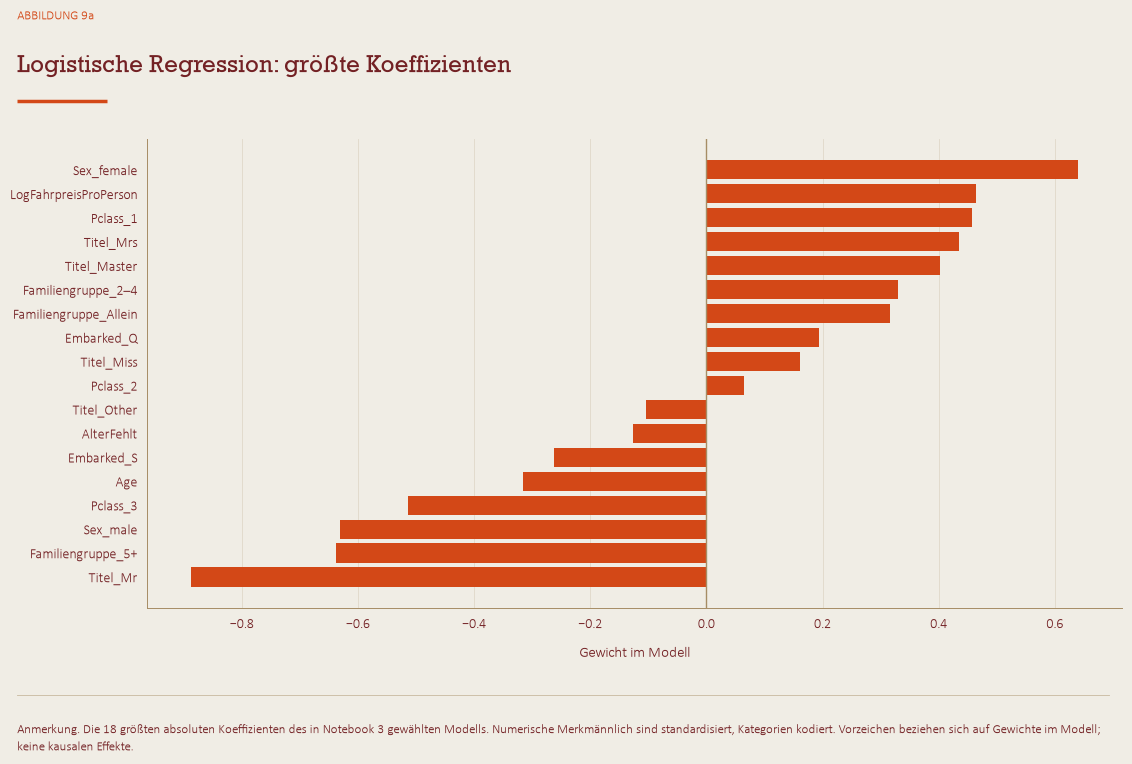

In [4]:
family = record['Familie']
estimator = model.named_steps['modell']
names = model.named_steps['vorbereitung'].get_feature_names_out()
table = pd.DataFrame({'Feature': names, 'Coefficient': estimator.coef_[0]})
display(table)
plot = table.reindex(table.Coefficient.abs().sort_values(ascending=False).head(18).index).sort_values('Coefficient')
fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(plot.Feature, plot.Coefficient, color=COLORS['accent1'])
ax.axvline(0, color=COLORS['accent2'], lw=1)
ax.set(xlabel='Gewicht im Modell', title='Logistic Regression: größte Koeffizienten')
filename = family.lower().replace(' ', '_') + '_erklaerung'
title = ax.get_title()
ax.set_title('')
numbers = {'Logistic Regression': '9a', 'Decision Tree': '9b', 'KNN': '9d'}
notes = {'Logistic Regression': 'Die 18 größten absoluten Koeffizienten des in Notebook 3 gewählten Modells. Numerische Merkmale sind standardisiert, Kategorien kodiert. Vorzeichen beziehen sich auf Log-Odds; keine kausalen Effekte.', 'Decision Tree': 'In Notebook 3 ausgewählter Baum, trainiert auf 712 Entwicklungspersonen. Gezeigt werden die ersten drei Ebenen; numerische Schwellen sind in Originaleinheiten zurückgerechnet. Vollständige Regeln stehen in decision_rules.txt.', 'KNN': 'Nachbarn der ersten Kontrollperson im verarbeiteten Merkmalsraum; Nachbarn stammen aus den 712 Entwicklungspersonen. Orange: überlebt; Salbei: nicht überlebt. Abstände hängen von Skalierung und Kodierung ab.'}
save_leaf_figure(fig, numbers[family], title, notes[family], FIGURES / filename)


## Kontrollvergleich und Vorhersage

Wir prüfen an den 179 Kontrollpersonen, wie oft die Vorhersage stimmt. Danach lernt das Modell mit allen 891 bekannten Personen und erstellt Vorhersagen für die 418 Testpersonen. Der Kontrollvergleich ändert die Modellwahl nicht.


In [5]:
prediction, probability = (model.predict(X_holdout), model.predict_proba(X_holdout)[:, 1])
holdout_metrics = pd.DataFrame([{'Methode': MODELL_TYP, **metrics(wahrheit, prediction, probability)}])
display(holdout_metrics)
final_model = clone(model).fit(daten.drop(columns='Survived'), daten.Survived)
classes, probabilities = (final_model.predict(test).astype(int), final_model.predict_proba(test)[:, 1])
submission = pd.DataFrame({'PassengerId': test.PassengerId, 'Survived': classes})
assert len(submission) == 418 and submission.PassengerId.equals(raw_test.PassengerId)
assert submission.Survived.isin([0, 1]).all() and np.isfinite(probabilities).all()
print(deutsch(f'{BEZEICHNUNGEN.get(MODELL_TYP, MODELL_TYP)}: {classes.sum()} von 418 als überlebt vorhergesagt. Kaggle-Score unbekannt.'))



,Methode,Genauigkeit,Anteil richtiger Überlebensvorhersagen,Anteil erkannter Überlebender,F1-Wert,Fläche unter der Prüfkurve,Wahrscheinlichkeitsfehler,Übereinstimmung über Zufallsniveau
0,Logistische Regression,0.8156,0.7903,0.7101,0.7481,0.8565,0.1377,0.6034


Logistische Regression: 168 von 418 als überlebt vorhergesagt. Kaggle-Score unbekannt.


## Quellen

Daten: `train.csv` und `test.csv`. Aufgabenstellung: `Task_description.pdf`. Fachliche Grundlage: Lisa Grobelscheg, *Skriptum LV DSM, ITW 26/27* (`Skriptum.pdf`).

KI-Unterstützung wurde für Code, Abbildungen und Erklärungen verwendet.
